<a href="https://colab.research.google.com/github/ova867/nomina/blob/main/aves_y_conejos_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install -q icrawler
import glob, shutil, cv2
import numpy as np
import tensorflow as tf
from icrawler.builtin import BingImageCrawler

shutil.rmtree('fotos', ignore_errors=True)
busquedas = {
    'conejos': ['pet rabbit photo', 'wild rabbit sitting on grass', 'rabbit animal close up'],
    'aves': ['bird perched on branch', 'wild bird photography', 'small bird close up'],
}
for carpeta, consultas in busquedas.items():
    for i, consulta in enumerate(consultas):
        BingImageCrawler(storage={'root_dir': f'fotos/{carpeta}'}, log_level=40).crawl(
            keyword=consulta, max_num=250, file_idx_offset=i * 250)

imagenes, etiquetas = [], []
for etiqueta, carpeta in enumerate(['conejos', 'aves']):   # 0 = conejo, 1 = ave
    for ruta in glob.glob(f'fotos/{carpeta}/*'):
        img = cv2.imread(ruta)
        if img is None:
            continue
        imagenes.append(cv2.resize(img, (100, 100)))
        etiquetas.append(etiqueta)

imagenes = np.array(imagenes)
etiquetas = np.array(etiquetas, dtype='int64')
datos = {'train': tf.data.Dataset.from_tensor_slices((imagenes, etiquetas)).shuffle(len(imagenes), seed=42, reshuffle_each_iteration=False)}
print(len(imagenes), np.bincount(etiquetas))

ERROR:downloader:Response status code 403, file https://www.optimumpm.com/wp-content/uploads/2024/09/pet-policies-creating-harmony-for-pet-owners-and-non-pet-owners-1697x1080.jpg
ERROR:downloader:Exception caught when downloading file https://cdn.petzlover.com/petzlover/www/1791723490/css/images/home_puppy_sell_buy.jpg, error: HTTPConnectionPool(host='www.petzlovers.com', port=8880): Read timed out. (read timeout=5), remaining retry times: 2
ERROR:downloader:Exception caught when downloading file https://cdn.petzlover.com/petzlover/www/1791723490/css/images/home_puppy_sell_buy.jpg, error: HTTPConnectionPool(host='www.petzlovers.com', port=8880): Read timed out. (read timeout=5), remaining retry times: 1
ERROR:downloader:Exception caught when downloading file https://cdn.petzlover.com/petzlover/www/1791723490/css/images/home_puppy_sell_buy.jpg, error: HTTPConnectionPool(host='www.petzlovers.com', port=8880): Read timed out. (read timeout=5), remaining retry times: 0
ERROR:downloader:Res

176 [ 41 135]


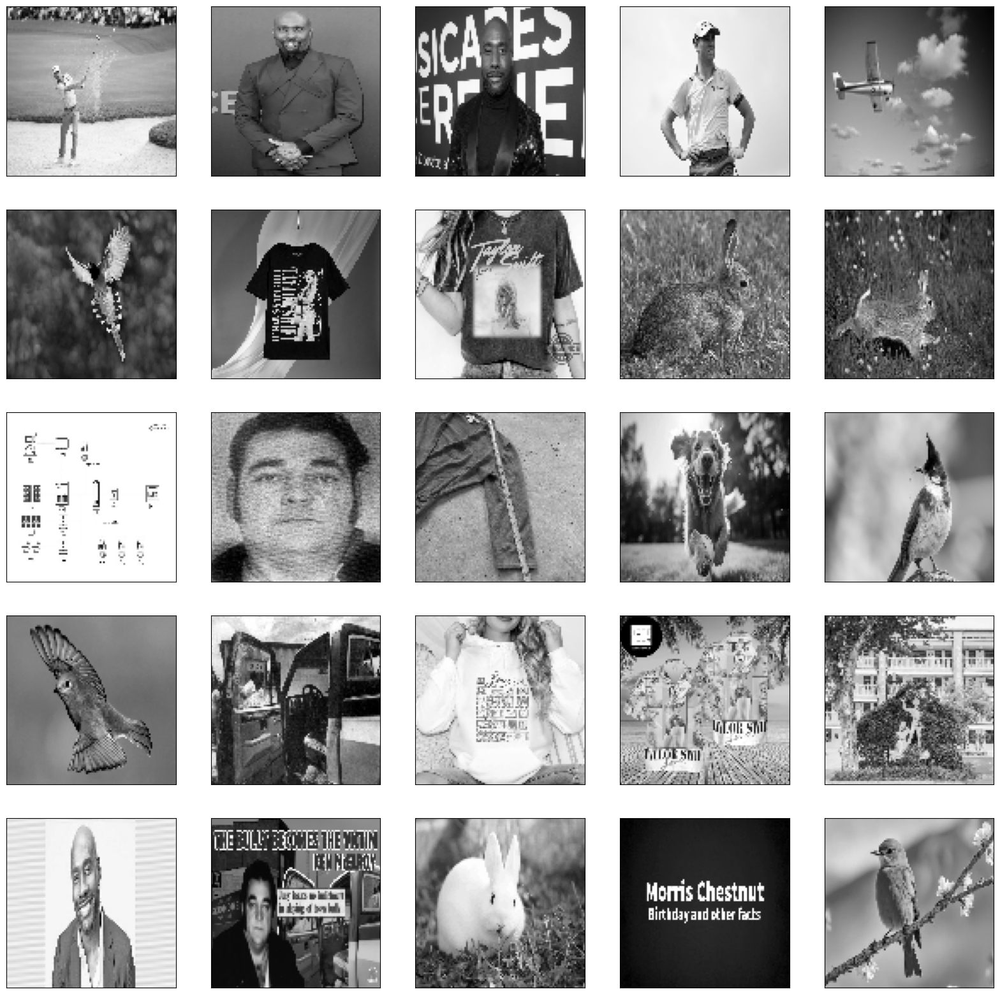

In [5]:
#Manipular y visualizar el set
#Lo pasamos a TAMANO_IMG (100x100) y a blanco y negro (solo para visualizar)
import matplotlib.pyplot as plt
import cv2

plt.figure(figsize=(20,20))

TAMANO_IMG=100

for i, (imagen, etiqueta) in enumerate(datos['train'].take(25)):
  imagen = cv2.resize(imagen.numpy(), (TAMANO_IMG, TAMANO_IMG))
  imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
  plt.subplot(5, 5, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(imagen, cmap='gray')

In [6]:
#Variable que contendra todos los pares de los datos (imagen y etiqueta) ya modificados (blanco y negro, 100x100)
datos_entrenamiento = []

for i, (imagen, etiqueta) in enumerate(datos['train']): #Todos los datos
  imagen = cv2.resize(imagen.numpy(), (TAMANO_IMG, TAMANO_IMG))
  imagen = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
  imagen = imagen.reshape(TAMANO_IMG, TAMANO_IMG, 1) #Cambiar tamano a 100,100,1
  datos_entrenamiento.append([imagen, etiqueta])

print(len(datos_entrenamiento))

#Preparar mis variables X (entradas) y y (etiquetas) separadas
X = [] #imagenes de entrada (pixeles)
y = [] #etiquetas (conejo o ave)

for imagen, etiqueta in datos_entrenamiento:
  X.append(imagen)
  y.append(etiqueta)

#Normalizar los datos de las X (imagenes). Se pasan a numero flotante y dividen entre 255 para quedar de 0-1 en lugar de 0-255
import numpy as np
X = np.array(X).astype(float) / 255

#Convertir etiquetas en arreglo simple
y = np.array(y)

print(X.shape)

176
(176, 100, 100, 1)


In [7]:
modeloDenso = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(100, 100, 1)),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(100, 100, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(100, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN2 = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(100, 100, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Dropout(0.5),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(250, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

#Compilar modelos. Usar crossentropy binario ya que tenemos solo 2 opciones (conejo o ave)
modeloDenso.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
modeloCNN.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
modeloCNN2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
from tensorflow.keras.callbacks import TensorBoard

tensorboardDenso = TensorBoard(log_dir='logs/denso')
modeloDenso.fit(X, y, batch_size=32, validation_split=0.15, epochs=20, callbacks=[tensorboardDenso])

tensorboardCNN = TensorBoard(log_dir='logs/cnn')
modeloCNN.fit(X, y, batch_size=32, validation_split=0.15, epochs=20, callbacks=[tensorboardCNN])

tensorboardCNN2 = TensorBoard(log_dir='logs/cnn2')
modeloCNN2.fit(X, y, batch_size=32, validation_split=0.15, epochs=20, callbacks=[tensorboardCNN2])

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 596ms/step - accuracy: 0.5503 - loss: 1.9069 - val_accuracy: 0.7778 - val_loss: 1.0917
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.7651 - loss: 1.5670 - val_accuracy: 0.7778 - val_loss: 0.5250
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5570 - loss: 0.7261 - val_accuracy: 0.7778 - val_loss: 0.7035
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6980 - loss: 0.7273 - val_accuracy: 0.7778 - val_loss: 0.5995
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7651 - loss: 0.5786 - val_accuracy: 0.7778 - val_loss: 0.5299
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7651 - loss: 0.5611 - val_accuracy: 0.7778 - val_loss: 0.5267
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7651 - loss: 0.5668 - val_accuracy: 0.7778 - val_loss: 0.5685
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7651 - loss: 0.5446 - val_accuracy: 0.7778 - val_loss: 0.5226

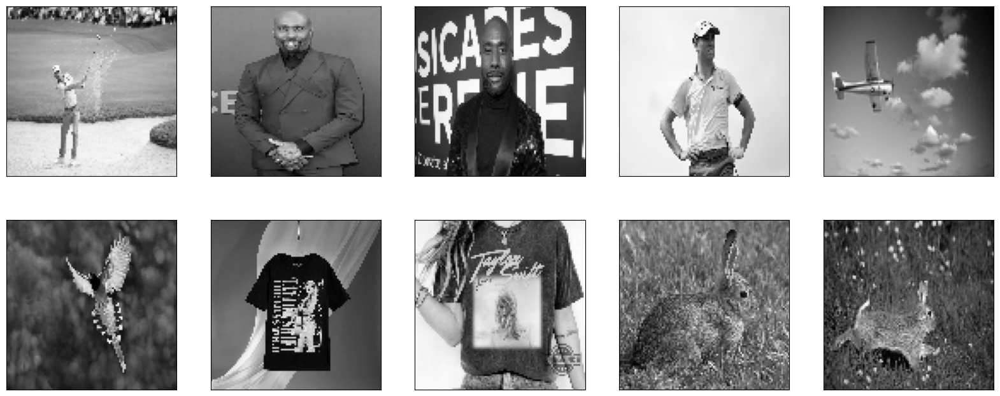

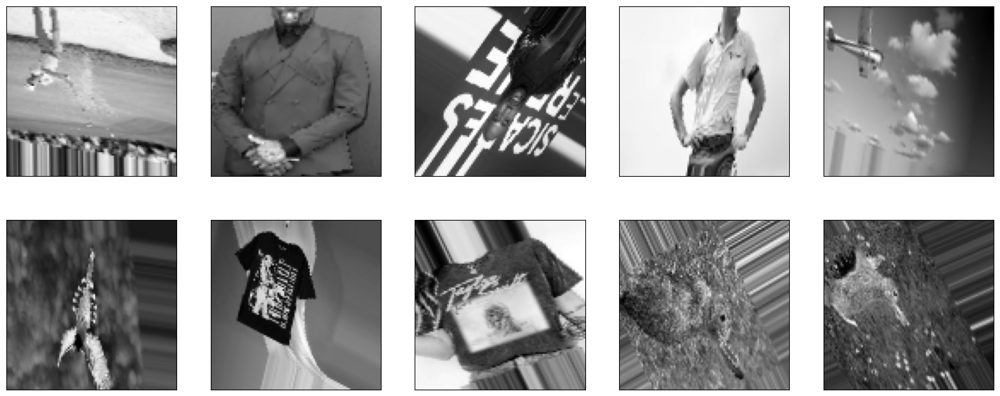

In [9]:
#ver las imagenes de la variable X sin modificaciones por aumento de datos
plt.figure(figsize=(20, 8))
for i in range(10):
  plt.subplot(2, 5, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(X[i].reshape(100, 100), cmap="gray")

#Realizar el aumento de datos con varias transformaciones. Al final, graficar 10 como ejemplo
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=15,
    zoom_range=[0.7, 1.4],
    horizontal_flip=True,
    vertical_flip=True
)

datagen.fit(X)

plt.figure(figsize=(20,8))

for imagen, etiqueta in datagen.flow(X, y, batch_size=10, shuffle=False):
  for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(imagen[i].reshape(100, 100), cmap="gray")
  break

In [10]:
modeloDenso_AD = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(100, 100, 1)),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(150, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN_AD = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(100, 100, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(100, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloCNN2_AD = tf.keras.models.Sequential([
  tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(100, 100, 1)),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),
  tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
  tf.keras.layers.MaxPooling2D(2, 2),

  tf.keras.layers.Dropout(0.5),
  tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(250, activation='relu'),
  tf.keras.layers.Dense(1, activation='sigmoid')
])

modeloDenso_AD.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
modeloCNN_AD.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
modeloCNN2_AD.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [11]:
#Separar los datos de entrenamiento y los datos de pruebas en variables diferentes
corte = int(len(X) * .85)

X_entrenamiento = X[:corte]
X_validacion = X[corte:]

y_entrenamiento = y[:corte]
y_validacion = y[corte:]

#Usar la funcion flow del generador para crear un iterador que podamos enviar como entrenamiento a la funcion FIT del modelo
data_gen_entrenamiento = datagen.flow(X_entrenamiento, y_entrenamiento, batch_size=32)

In [12]:
tensorboardDenso_AD = TensorBoard(log_dir='logs/denso_AD')
modeloDenso_AD.fit(
    data_gen_entrenamiento,
    epochs=20,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardDenso_AD]
)

tensorboardCNN_AD = TensorBoard(log_dir='logs-new/cnn_AD')
modeloCNN_AD.fit(
    data_gen_entrenamiento,
    epochs=20,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardCNN_AD]
)

tensorboardCNN2_AD = TensorBoard(log_dir='logs/cnn2_AD')
modeloCNN2_AD.fit(
    data_gen_entrenamiento,
    epochs=20,
    validation_data=(X_validacion, y_validacion),
    steps_per_epoch=int(np.ceil(len(X_entrenamiento) / float(32))),
    validation_steps=int(np.ceil(len(X_validacion) / float(32))),
    callbacks=[tensorboardCNN2_AD]
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 280ms/step - accuracy: 0.6376 - loss: 1.7675 - val_accuracy: 0.7778 - val_loss: 0.7288
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5906 - loss: 1.0823 - val_accuracy: 0.7778 - val_loss: 0.5418
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.7517 - loss: 0.6587 - val_accuracy: 0.7778 - val_loss: 0.5260
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.7383 - loss: 0.5898 - val_accuracy: 0.7778 - val_loss: 0.5567
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6242 - loss: 0.6727 - val_accuracy: 0.7778 - val_loss: 0.6467
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.6376 - loss: 0.7894 - val_accuracy: 0.2222 - val_loss: 0.9371
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.6644 - loss: 0.8393 - val_accuracy: 0.7778 - val_loss: 0.5319
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.6779 - loss: 0.6256 - val_accuracy: 0.7778 - val_loss: 0.5568

In [13]:
modeloCNN_AD.save('conejos-aves-cnn-ad.h5')

In [14]:
!pip install tensorflowjs
!mkdir carpeta_salida
!tensorflowjs_converter --input_format keras conejos-aves-cnn-ad.h5 carpeta_salida

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.2/15.2 MB 69.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
INFO: pip is looking at multiple versions of tensorflow-decision-forests to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of tensorflow-decision-forests to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
INFO: pip is looking at multiple versions of tensorflow to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of tensorflow to determine which version is compatible with other requirements. This could take a while.
IN

/usr/local/lib/python3.13/dist-packages/tensorflowjs/read_weights.py:28: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  np.uint8, np.uint16, np.object, np.bool]
Traceback (most recent call last):
  File "/usr/local/bin/tensorflowjs_converter", line 5, in <module>
    from tensorflowjs.converters.converter import pip_main
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/__init__.py", line 21, in <module>
    from tensorflowjs import converters
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/converters/__init__.py", line 21, in <module>
    from tensorflowjs.converters.converter import convert
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/converters/converter.py", line 35, in <module>
    from tensorflowjs.converters import keras_h5_conversion as conversion
  File "/usr/local/lib/python3.13/dist-packages/tensorflowjs/converters/keras_h5_conversion.py", line 33, in <module>
    from tensorflowjs import 

In [15]:
%load_ext tensorboard
%tensorboard --logdir logs

<IPython.core.display.Javascript object>